# Análise de vendas: paçoca e rolhas

Relatório sobre as vendas de **paçoca** e **rolhas** da ZePequeno, por região e canal de venda.

**Como ler:** o relatório vai do geral para o específico (visão geral, produtos, região, canal, um mês). Cada seção responde a uma pergunta e tem três partes: a tabela ou gráfico, frases com os números calculados e um espaço para a **sua interpretação**. A qualidade dos dados fica no anexo final.

**Pontos de atenção sobre os dados (valem para tudo abaixo):**
- As datas são sempre o **dia 1 de cada mês**. Por isso não há análise por dia da semana.
- Não há vendas de **maio a agosto de 2026**, e há **uma única venda em setembro de 2026**.
- A grande maioria das vendas é da região **sul**.
- "Venda boa, média ou ruim" compara o valor da venda com a **média do produto** (±10%), considerando todas as vendas limpas dele.
- Só há o valor total da venda, sem quantidade. Por isso falamos de **valor médio por venda (ticket médio)** e não de preço por unidade.



In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import analise as a

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

# formata valores em reais: 1234.5 -> R$ 1.234,50
brl = lambda v: f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
vendas = a.df

ModuleNotFoundError: No module named 'pandas'

## 1. Visão geral

**Pergunta:** quanto foi vendido no total, e como as vendas se distribuem ao longo do tempo?

In [ ]:
total = vendas["Valor_Venda"].sum()
n = len(vendas)
print(f"Foram analisadas {n} vendas, de {vendas['Data'].min():%m/%Y} a {vendas['Data'].max():%m/%Y}, somando {brl(total)}.")
print(f"Ticket médio geral: {brl(vendas['Valor_Venda'].mean())} (mediana {brl(vendas['Valor_Venda'].median())}).")

resumo = a.vendas_por_regiao()[["boa", "média", "ruim"]].sum()
print("Classificação das vendas em relação à média do próprio produto (±10%):")
for classe, qtd in resumo.items():
    print(f"  - {classe}: {qtd} vendas ({qtd / n:.0%})")

por_ano = vendas.groupby("Ano")["Valor_Venda"].agg(total="sum", vendas="count")
display(por_ano.round(2))

Foram analisadas 716 vendas, de 01/2022 a 09/2026, somando R$ 1.477.926,07.
Ticket médio geral: R$ 2.064,14 (mediana R$ 2.075,50).
Classificação das vendas em relação à média do próprio produto (±10%):
  - boa: 261 vendas (36%)
  - média: 201 vendas (28%)
  - ruim: 254 vendas (35%)


,total,vendas
Ano,,
2022,221780.50,101
2023,313711.00,152
2024,405457.00,195
2025,340477.00,171
2026,196500.57,97


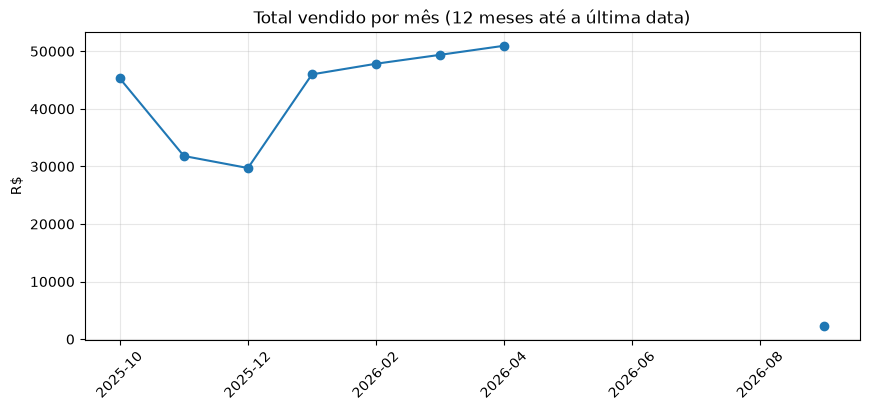

Meses sem nenhuma venda na janela: 2026-05, 2026-06, 2026-07, 2026-08.
Mês de maior valor vendido: 2026-04 (R$ 50.962,00).


In [ ]:
serie = a.comparacao_produtos(12)
total_mensal = serie.sum(axis=1, min_count=1)
sem_dados = [str(m) for m in serie.index[serie.isna().all(axis=1)]]

ax = total_mensal.rename(index=str).plot(marker="o", title="Total vendido por mês (12 meses até a última data)")
ax.set_ylabel("R$")
plt.xticks(rotation=45)
plt.show()

print(f"Meses sem nenhuma venda na janela: {', '.join(sem_dados) if sem_dados else 'nenhum'}.")
mes_max = total_mensal.idxmax()
print(f"Mês de maior valor vendido: {mes_max} ({brl(total_mensal.max())}).")

### Faixas de valor (quartis)

Cada venda é colocada em uma de quatro faixas: **baixa**, **média-baixa**, **média-alta** e **alta**, de acordo com os quartis dos valores. `FaixaProduto` compara a venda só com as do mesmo produto; `FaixaGeral` compara com todas.

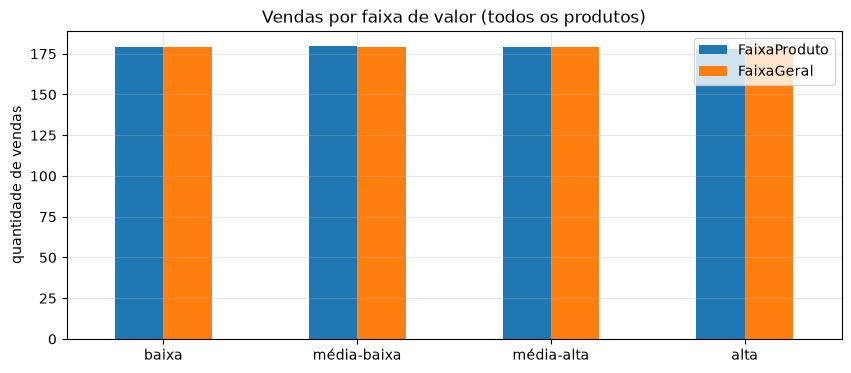

paçoca: faixa geral 'alta' tem 60 vendas e 'baixa' tem 107.
rolhas: faixa geral 'alta' tem 119 vendas e 'baixa' tem 72.


In [ ]:
faixas = a.distribuicao_faixas()
ax = faixas.plot.bar(rot=0, title="Vendas por faixa de valor (todos os produtos)")
ax.set_ylabel("quantidade de vendas")
plt.show()

for produto in ["paçoca", "rolhas"]:
    f = a.distribuicao_faixas(produto=produto)
    print(f"{produto}: faixa geral 'alta' tem {f.loc['alta', 'FaixaGeral']} vendas e 'baixa' tem {f.loc['baixa', 'FaixaGeral']}.")

## 2. Comparação entre produtos

**Pergunta:** qual produto vende mais, e isso muda ao longo do tempo?

Duas janelas de 12 meses são mostradas. A da esquerda é de **calendário**: termina na data mais recente e deixa a lacuna visível. A da direita pega os **12 últimos meses que têm vendas**, sem os meses vazios.

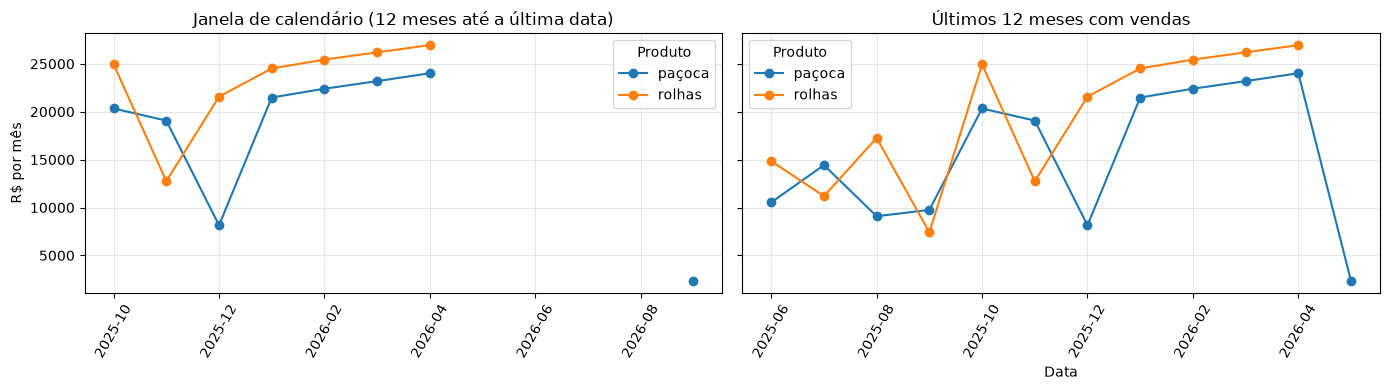

Janela de calendário (12 meses até a última data):
  - rolhas vendeu mais que paçoca em 6 dos 8 meses com dados.
  - total: paçoca R$ 140.966,57 | rolhas R$ 162.350,00.
Últimos 12 meses com vendas:
  - rolhas vendeu mais que paçoca em 8 dos 12 meses com dados.
  - total: paçoca R$ 184.768,57 | rolhas R$ 213.044,00.


In [ ]:
janelas = [
    ("Janela de calendário (12 meses até a última data)", a.comparacao_produtos(12)),
    ("Últimos 12 meses com vendas", a.comparacao_produtos(12, somente_meses_com_dados=True)),
]

fig, eixos = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (titulo, serie) in zip(eixos, janelas):
    serie.rename(index=str).plot(ax=ax, marker="o", title=titulo)
    ax.set_ylabel("R$ por mês")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

for titulo, serie in janelas:
    com_dados = serie.dropna(how="all")
    meses_rolhas = int((com_dados["rolhas"] > com_dados["paçoca"]).sum())
    print(f"{titulo}:")
    print(f"  - rolhas vendeu mais que paçoca em {meses_rolhas} dos {len(com_dados)} meses com dados.")
    print(f"  - total: paçoca {brl(com_dados['paçoca'].sum())} | rolhas {brl(com_dados['rolhas'].sum())}.")

,ticket_medio,mediana,vendas
Produto,,,
paçoca,1987.59,1939.45,360
rolhas,2141.56,2190.00,356


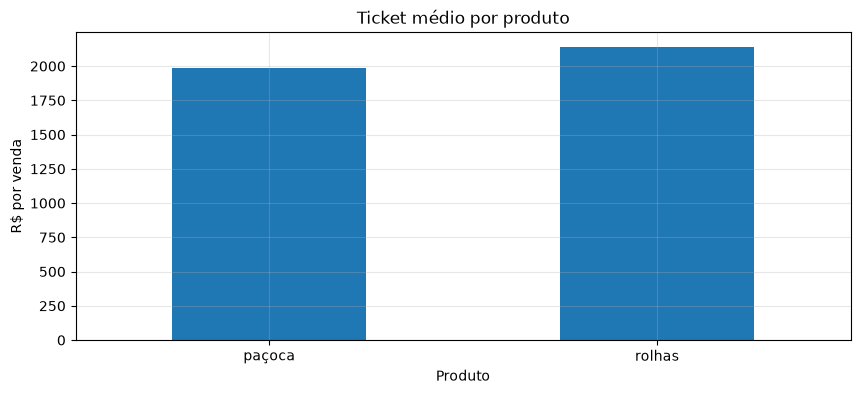

rolhas tem o maior ticket médio (R$ 2.141,56), 7.7% acima de paçoca (R$ 1.987,59).


In [ ]:
ticket = a.ticket_medio()
display(ticket)

ax = ticket["ticket_medio"].plot.bar(rot=0, title="Ticket médio por produto")
ax.set_ylabel("R$ por venda")
plt.show()

maior = ticket["ticket_medio"].idxmax()
menor = ticket["ticket_medio"].idxmin()
dif = ticket["ticket_medio"].max() / ticket["ticket_medio"].min() - 1
print(f"{maior} tem o maior ticket médio ({brl(ticket.loc[maior, 'ticket_medio'])}), {dif:.1%} acima de {menor} ({brl(ticket.loc[menor, 'ticket_medio'])}).")

## 3. Por região

**Pergunta:** onde as vendas acontecem e onde cada venda vale mais?

,total,vendas,ticket_medio,boa,média,ruim
Região,,,,,,
centro-oeste,6470.00,3,2156.67,1,1,1
nordeste,11270.00,5,2254.00,2,2,1
norte,5860.00,3,1953.33,2,0,1
sudeste,31160.00,15,2077.33,6,3,6
sul,1423166.07,690,2062.56,250,195,245


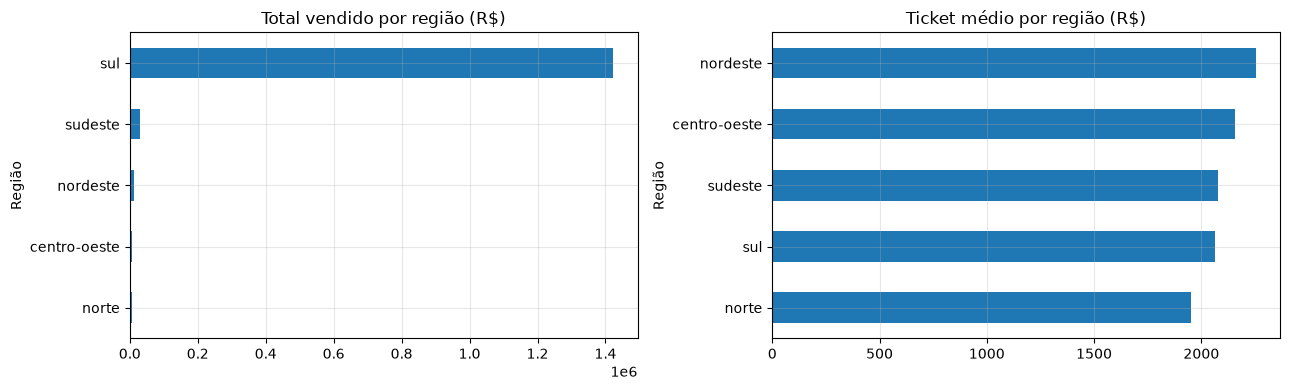

A região sul concentra 96% das vendas (690 de 716).
Maior ticket médio: nordeste (R$ 2.254,00).
Atenção: centro-oeste, nordeste, norte, sudeste têm menos de 20 vendas; a comparação com elas é frágil.


In [ ]:
regiao = a.vendas_por_regiao()
display(regiao)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
regiao["total"].sort_values().plot.barh(ax=eixos[0], title="Total vendido por região (R$)")
regiao["ticket_medio"].sort_values().plot.barh(ax=eixos[1], title="Ticket médio por região (R$)")
plt.tight_layout()
plt.show()

participacao = regiao["vendas"] / regiao["vendas"].sum()
print(f"A região {participacao.idxmax()} concentra {participacao.max():.0%} das vendas ({regiao['vendas'].max()} de {regiao['vendas'].sum()}).")
print(f"Maior ticket médio: {regiao['ticket_medio'].idxmax()} ({brl(regiao['ticket_medio'].max())}).")
poucas = regiao[regiao["vendas"] < 20].index.tolist()
print(f"Atenção: {', '.join(poucas)} têm menos de 20 vendas; a comparação com elas é frágil.")

### Dentro do sul, por cidade

In [ ]:
sul = a.df[a.df["Região"] == "sul"]
cidades = sul.groupby("Cidade")["Valor_Venda"].agg(total="sum", vendas="count", ticket_medio="mean").round(2)
display(cidades.sort_values("total", ascending=False))
print(f"Linhas do sul sem cidade informada: {int(sul['Cidade'].isna().sum())}.")

,total,vendas,ticket_medio
Cidade,,,
joinville,539695.47,254,2124.79
florianópolis,438976.80,214,2051.29
blumenau,427186.80,213,2005.57
curitiba,5350.00,3,1783.33


Linhas do sul sem cidade informada: 6.


## 4. Por canal

**Pergunta:** vende-se mais em loja física ou no e-commerce, e isso muda de produto para produto?

,total,vendas,ticket_medio,boa,média,ruim
Canal,,,,,,
e-commerce,711943.57,350,2034.12,120,91,139
loja física,765982.50,366,2092.85,141,110,115


,paçoca,rolhas
Canal,,
e-commerce,1944.25,2122.98
loja física,2028.13,2159.73


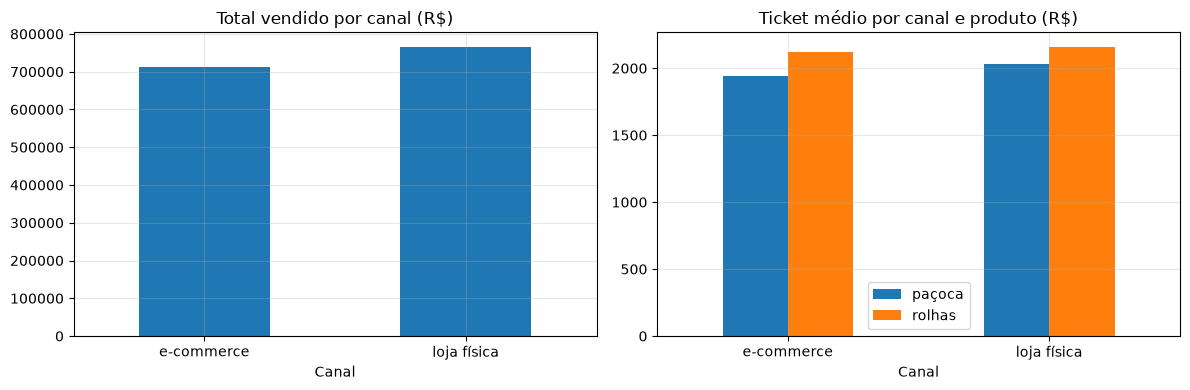

O canal com maior total é loja física (R$ 765.982,50, 52% do valor).
Quantidade de vendas: e-commerce 350, loja física 366.


In [ ]:
canal = a.vendas_por_canal()
display(canal)

por_produto = pd.DataFrame({
    produto: a.vendas_por_canal(produto=produto)["ticket_medio"] for produto in ["paçoca", "rolhas"]
})
display(por_produto)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
canal["total"].plot.bar(ax=eixos[0], rot=0, title="Total vendido por canal (R$)")
por_produto.plot.bar(ax=eixos[1], rot=0, title="Ticket médio por canal e produto (R$)")
plt.tight_layout()
plt.show()

lider = canal["total"].idxmax()
print(f"O canal com maior total é {lider} ({brl(canal['total'].max())}, {canal['total'].max() / canal['total'].sum():.0%} do valor).")
print(f"Quantidade de vendas: " + ", ".join(f"{c} {int(q)}" for c, q in canal["vendas"].items()) + ".")

## 5. Um mês específico

**Pergunta:** como foi um mês em particular? Altere `ano` e `mes` na célula abaixo para olhar outro período.

In [ ]:
ano, mes = 2026, 4

tabela = a.vendas_por_mes(ano, mes)
if tabela.empty:
    print(f"Não há vendas em {mes:02d}/{ano}.")
else:
    display(tabela)
    print(f"Em {mes:02d}/{ano}: {int(tabela['vendas'].sum())} vendas, somando {brl(tabela['total'].sum())}.")
    for produto, linha in tabela.iterrows():
        print(f"  - {produto}: {int(linha['vendas'])} vendas, ticket médio {brl(linha['ticket_medio'])}, "
              f"{int(linha['boa'])} boas, {int(linha['média'])} médias e {int(linha['ruim'])} ruins.")

,total,vendas,ticket_medio,boa,média,ruim
Produto,,,,,,
paçoca,24015.0,12,2001.25,3,6,3
rolhas,26947.0,12,2245.58,5,4,3


Em 04/2026: 24 vendas, somando R$ 50.962,00.
  - paçoca: 12 vendas, ticket médio R$ 2.001,25, 3 boas, 6 médias e 3 ruins.
  - rolhas: 12 vendas, ticket médio R$ 2.245,58, 5 boas, 4 médias e 3 ruins.


## Anexo: qualidade dos dados

Antes da análise, a limpeza separou as vendas em três grupos. Esta parte mostra o que foi retirado das análises acima e por quê.

In [ ]:
pasta_dados = a.pasta / "data"
suspeitas = pd.read_csv(pasta_dados / "vendas_suspeitas.csv")
canceladas = pd.read_csv(pasta_dados / "vendas_canceladas.csv")
limites = pd.read_csv(pasta_dados / "limites_iqr.csv", index_col="Produto")

total_bruto = len(vendas) + len(suspeitas) + len(canceladas)
print(f"Linhas originais: {total_bruto}")
print(f"  - usadas na análise: {len(vendas)}")
print(f"  - suspeitas (fora do padrão): {len(suspeitas)}")
print(f"  - canceladas/devoluções (valor 0): {len(canceladas)}")

Linhas originais: 763
  - usadas na análise: 716
  - suspeitas (fora do padrão): 26
  - canceladas/devoluções (valor 0): 21


### Vendas suspeitas

Entram aqui valores `999999` (ou vazios) e valores fora dos limites da **regra do IQR** (1,5 × a distância entre o 1º e o 3º quartil), calculada **para cada produto**. A regra é uma convenção: outro fator mudaria quais vendas são retiradas.

In [ ]:
display(limites.round(2))
display(suspeitas.groupby(["Produto", "Motivo"])["Valor_Venda"].agg(["count", "min", "max"]))

acima = suspeitas[suspeitas["Motivo"] == "acima do limite"]["Valor_Venda"]
abaixo = suspeitas[suspeitas["Motivo"] == "abaixo do limite"]["Valor_Venda"]
print(f"Acima do limite: {len(acima)} vendas, de {acima.min():,.0f} a {acima.max():,.0f}.")
print(f"Abaixo do limite: {len(abaixo)} vendas, de {abaixo.min():,.0f} a {abaixo.max():,.0f}.")
print(f"Maior e menor valor mantidos: {vendas['Valor_Venda'].max():,.0f} e {vendas['Valor_Venda'].min():,.0f}.")

,Q1,Q3,IQR,Limite_Inferior,Limite_Superior
Produto,,,,,
paçoca,1635.0,2300.00,665.00,637.50,3297.50
rolhas,1752.5,2526.25,773.75,591.88,3686.88


count       min       max
Produto Motivo                                     
paçoca  999999 ou vazio       3  999999.0  999999.0
        abaixo do limite      8       2.0     560.0
        acima do limite       1  123456.0  123456.0
rolhas  abaixo do limite     10       1.0     556.0
        acima do limite       4   99999.0  123456.0

Acima do limite: 5 vendas, de 99,999 a 123,456.
Abaixo do limite: 18 vendas, de 1 a 560.
Maior e menor valor mantidos: 2,991 e 670.


### Vendas canceladas ou devolvidas (valor 0)

In [ ]:
display(canceladas.groupby(["Produto", "Canal"]).size().rename("quantidade").to_frame())
print(f"Total de linhas com valor 0: {len(canceladas)} ({len(canceladas) / total_bruto:.1%} das linhas originais).")

quantidade
Produto Canal                  
paçoca  e-commerce            8
        loja física           3
rolhas  e-commerce            3
        loja física           7

Total de linhas com valor 0: 21 (2.8% das linhas originais).
